In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

## /kaggle/input/datasets/blueblushed/hospital-dataset-for-practice/hospital data analysis.csv

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r"C:\Users\CHANDAN KUMAR\Downloads\hospital data analysis.csv")

In [5]:
df.head(10)

,Patient_ID,Age,Gender,Condition,Procedure,Cost,Length_of_Stay,Readmission,Outcome,Satisfaction
0,1,45,Female,Heart Disease,Angioplasty,15000,5,No,Recovered,4
1,2,60,Male,Diabetes,Insulin Therapy,2000,3,Yes,Stable,3
2,3,32,Female,Fractured Arm,X-Ray and Splint,500,1,No,Recovered,5
3,4,75,Male,Stroke,CT Scan and Medication,10000,7,Yes,Stable,2
4,5,50,Female,Cancer,Surgery and Chemotherapy,25000,10,No,Recovered,4
5,6,68,Male,Hypertension,Medication and Counseling,1000,2,No,Stable,4
6,7,55,Female,Appendicitis,Appendectomy,8000,4,No,Recovered,3
7,8,40,Male,Fractured Leg,Cast and Physical Therapy,3000,6,No,Recovered,4
8,9,70,Female,Heart Attack,Cardiac Catheterization,18000,8,Yes,Stable,2
9,10,25,Male,Allergic Reaction,Epinephrine Injection,100,1,No,Recovered,5


In [6]:
#print the dimension of dataset
df.shape

(984, 10)

In [7]:
#dropping the patient id here
df.drop("Patient_ID",axis=1,inplace=True)

# univariate analysis

In [8]:
#separating the numeric columns

numdf=df.select_dtypes(include="number")

In [9]:
numdf.columns

Index(['Age', 'Cost', 'Length_of_Stay', 'Satisfaction'], dtype='str')

In [10]:
#histogram
#kdeplot
#boxplot

## Histogram of Age 

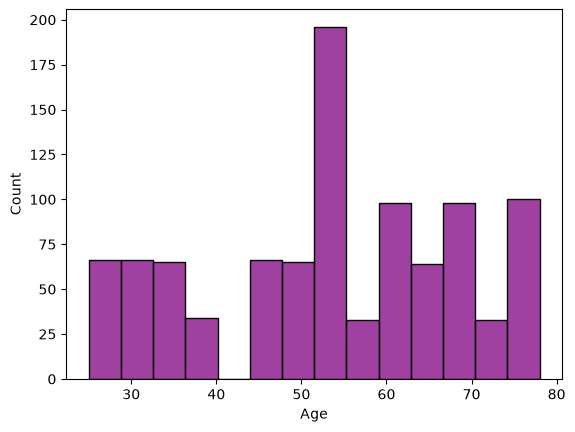

In [11]:
sns.histplot(x="Age",data=df,color="purple")
plt.show()
#discrete numeric

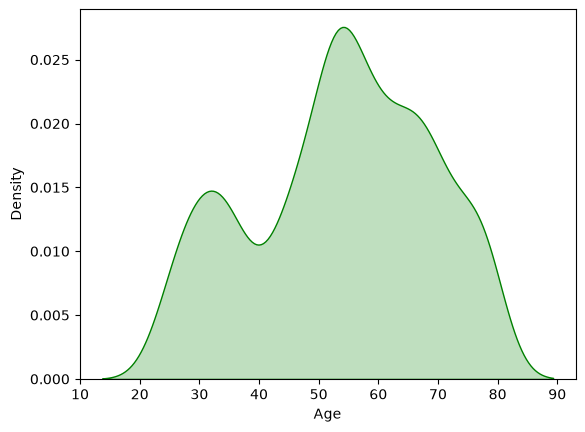

In [12]:
sns.kdeplot(x="Age",data=df,fill=True,color="green")
plt.show()
#looks normally distributed

In [13]:
df["Age"].skew()
#it shows slightly negatively skewed but it is normally distributed

np.float64(-0.24451527944972423)

In [14]:
print(df["Age"].mean())
print(df["Age"].median())

53.75406504065041
55.0


# age shows normally distributed mean slightly less than median so slight negatively skewed

## outlier analysis of age

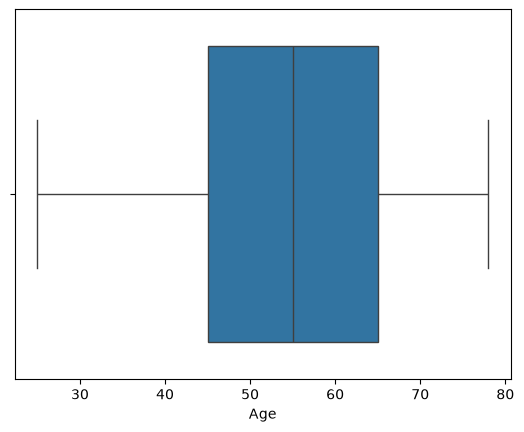

In [16]:
#outlier analysis
sns.boxplot(x="Age",data=df)
plt.show()
#The age column has not outliers

In [17]:
numdf.head()

,Age,Cost,Length_of_Stay,Satisfaction
0,45,15000,5,4
1,60,2000,3,3
2,32,500,1,5
3,75,10000,7,2
4,50,25000,10,4


## grid plot showing histogram and KDEplot  for all 4 columns

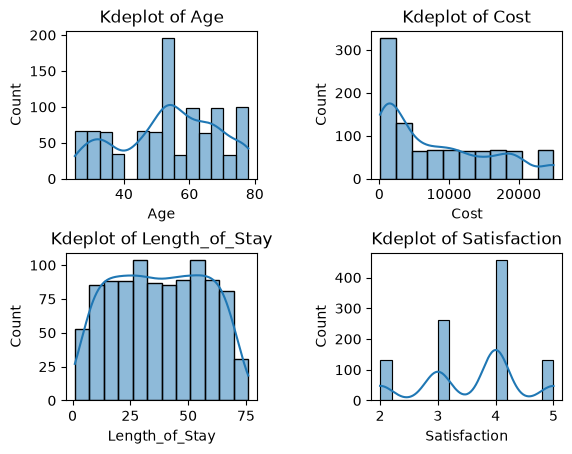

In [18]:
idx=1
for i in numdf.columns:
    plt.subplot(2,2,idx)
    plt.subplots_adjust(hspace=0.5,wspace=0.6)
    plt.title("Kdeplot of "+ i)
    sns.histplot(x=numdf[i],data=numdf,kde=True)
    idx=idx+1

## grid plot showing boxplot  for all 4 columns

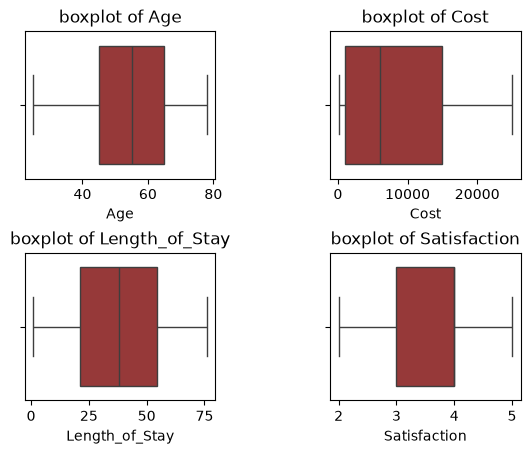

In [19]:
idx=1
for i in numdf.columns:
    plt.subplot(2,2,idx)
    plt.subplots_adjust(hspace=0.5,wspace=0.6)
    plt.title("boxplot of "+ i)
    sns.boxplot(x=numdf[i],data=numdf,color="brown")
    idx=idx+1
#none of the numeric columns have outliers

In [20]:
df["Cost"].skew()

np.float64(0.7213002455252782)

In [21]:
#Correlation plot

numdf.corr()

,Age,Cost,Length_of_Stay,Satisfaction
Age,1.000000,0.303816,0.075080,-0.750429
Cost,0.303816,1.000000,0.114206,-0.469658
Length_of_Stay,0.075080,0.114206,1.000000,-0.080891
Satisfaction,-0.750429,-0.469658,-0.080891,1.000000


1. Age has weak positive correlation with cost ,means if age increases cost also increases
2. Age has a strong negative correlation with satisfaction, if age increases , satisfaction decreases
3. Cost has weak negative correlation with satisfaction and weak posiive correlation with Age

# Multivariate analysis

## Correlation matrix of numeric columns

<Axes: >

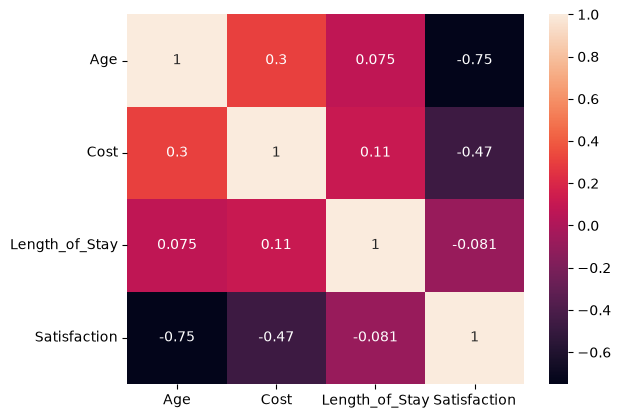

In [23]:
sns.heatmap(numdf.corr(),annot=True)

# Bivariate analysis

## scatter chart between age and customer satisfaction

<Axes: xlabel='Satisfaction', ylabel='Age'>

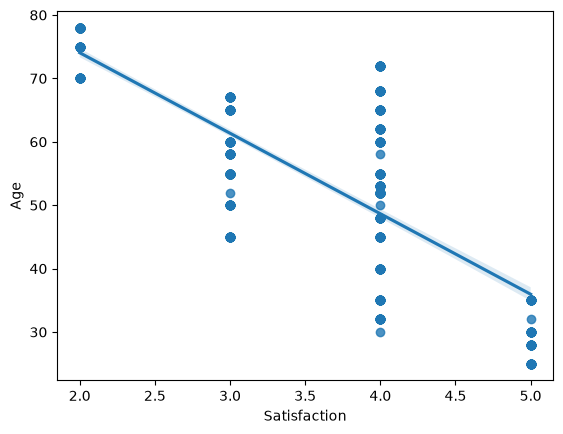

In [24]:
sns.regplot(x="Satisfaction",y="Age",data=df)
#strong negative correlation between a contoinuous numeric variable and discrete variable

## Relation between age and Cost of medical procedure using scatter chart

<Axes: xlabel='Age', ylabel='Cost'>

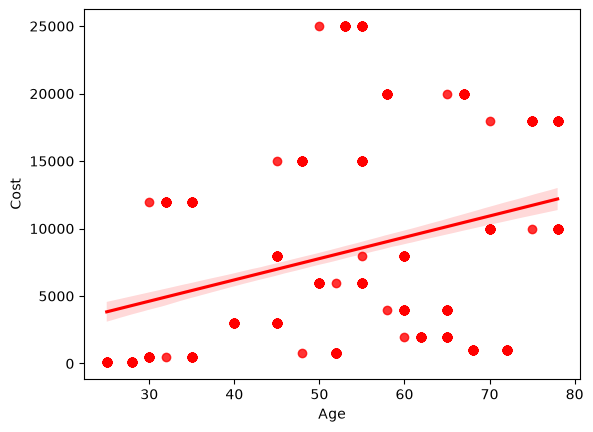

In [25]:
sns.regplot(x="Age",y="Cost",data=df,color="red")
#weak positive correlation

In [26]:
df.head()

,Age,Gender,Condition,Procedure,Cost,Length_of_Stay,Readmission,Outcome,Satisfaction
0,45,Female,Heart Disease,Angioplasty,15000,5,No,Recovered,4
1,60,Male,Diabetes,Insulin Therapy,2000,3,Yes,Stable,3
2,32,Female,Fractured Arm,X-Ray and Splint,500,1,No,Recovered,5
3,75,Male,Stroke,CT Scan and Medication,10000,7,Yes,Stable,2
4,50,Female,Cancer,Surgery and Chemotherapy,25000,10,No,Recovered,4


## analyse the medical  condition as per gender

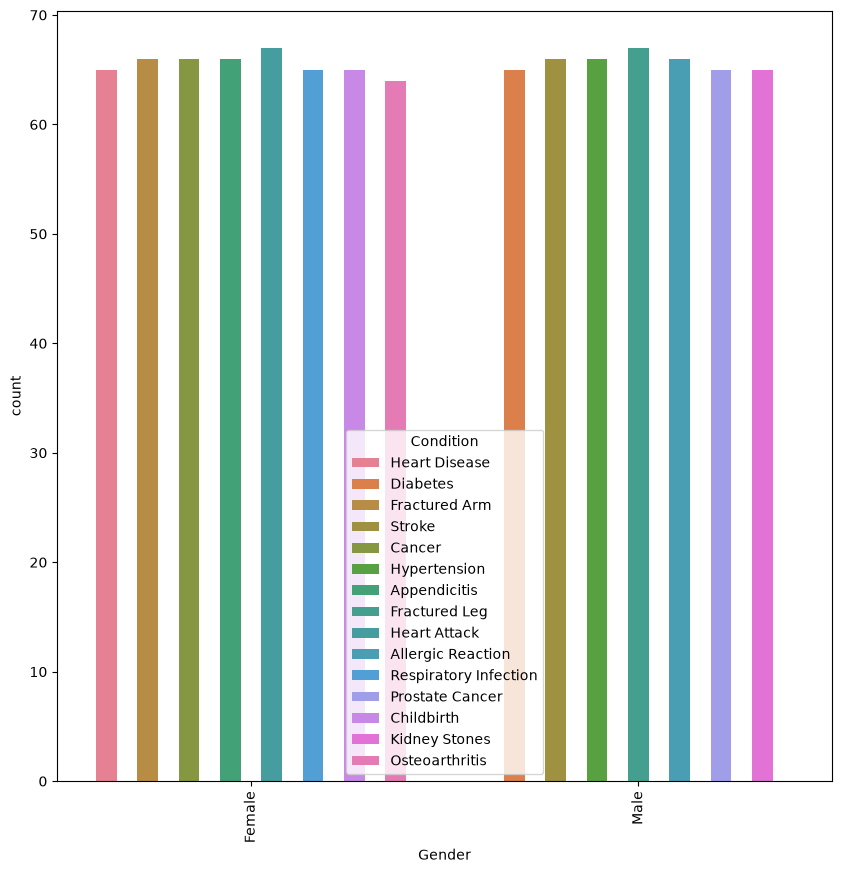

In [27]:
plt.figure(figsize=(10,10))
sns.countplot(x="Gender",data=df,hue="Condition")
plt.xticks(rotation='vertical')
plt.show()

## which procedure is most expensive with barchart

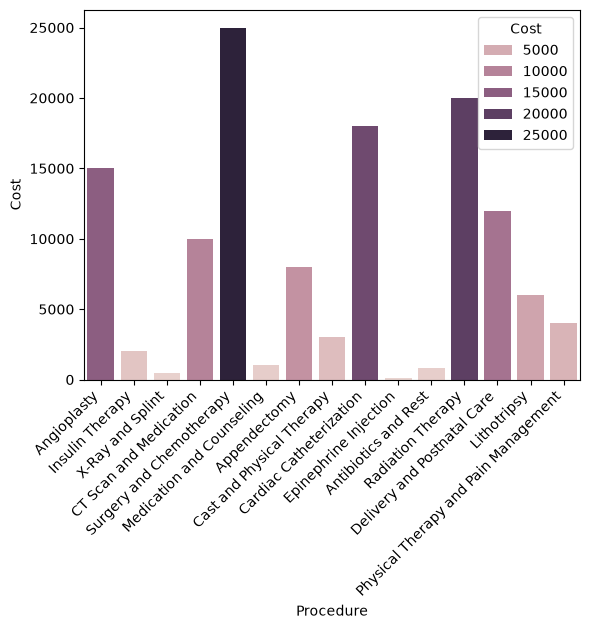

In [28]:
df_sorted = df.sort_values("Cost", ascending=False)
sns.barplot(x="Procedure",y="Cost",data=df,hue="Cost")
plt.xticks(rotation=45, ha='right')
plt.show()

In [29]:
#chemotherapy has highest cost and xray has lowest cost

In [30]:
#in the dataset males and females have different diseases recorded so cant compare

In [31]:
male=df[df.Gender=="Male"]
count_cond=male["Condition"].value_counts()
count_cond

Condition
Fractured Leg        67
Stroke               66
Hypertension         66
Allergic Reaction    66
Diabetes             65
Prostate Cancer      65
Kidney Stones        65
Name: count, dtype: int64

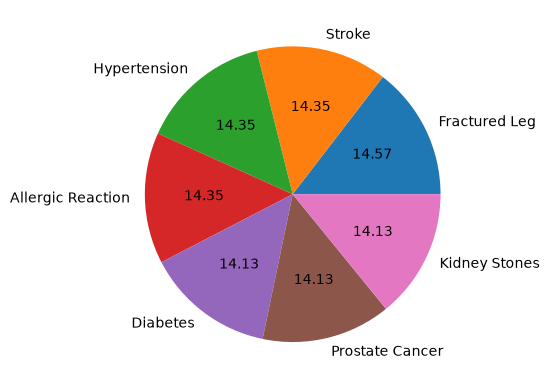

In [32]:
plt.pie(count_cond,labels=count_cond.index,autopct="%0.2f")
plt.show()

In [33]:
female=df[df.Gender=="Female"]
count_cond=female["Condition"].value_counts()
count_cond

Condition
Heart Attack             67
Fractured Arm            66
Cancer                   66
Appendicitis             66
Heart Disease            65
Respiratory Infection    65
Childbirth               65
Osteoarthritis           64
Name: count, dtype: int64

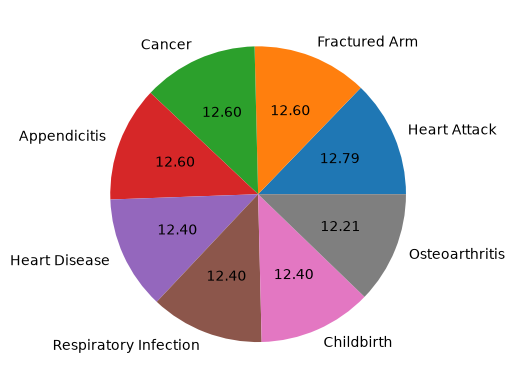

In [34]:
plt.pie(count_cond,labels=count_cond.index,autopct="%0.2f")
plt.show()

In [35]:
gr_stay=df.groupby("Condition")["Length_of_Stay"].mean()

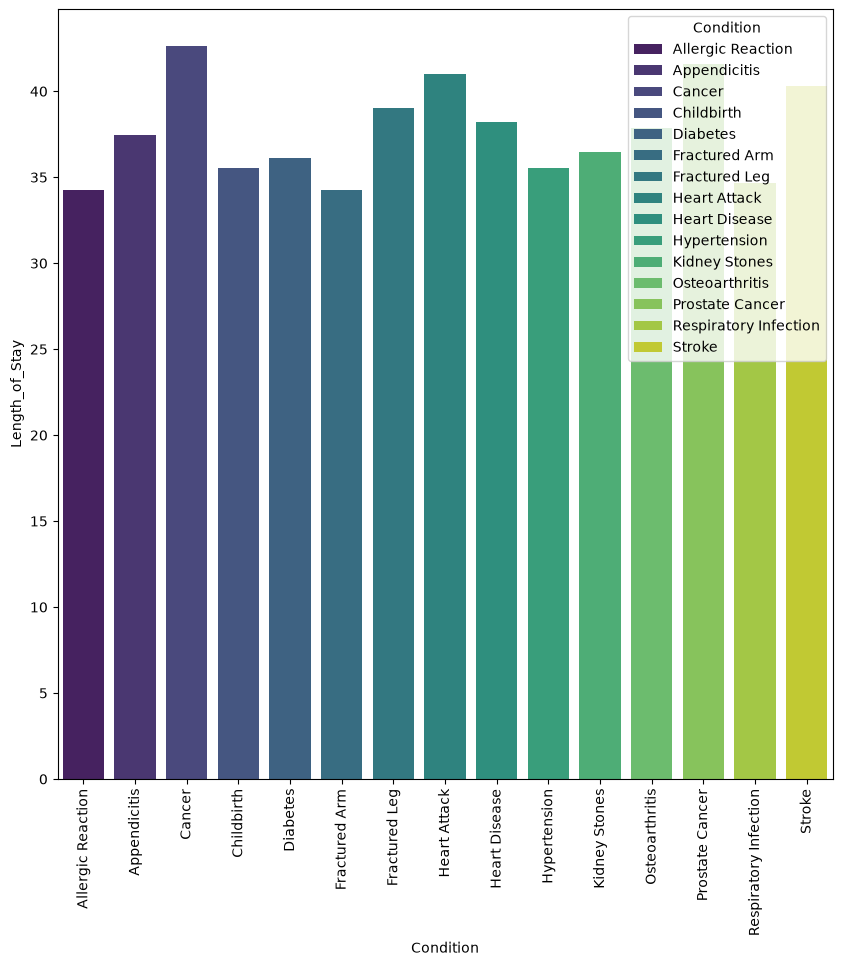

In [36]:
plt.figure(figsize=(10,10))
sns.barplot(x=gr_stay.index,y=gr_stay,hue=gr_stay.index,legend=True, palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

# The maximum stay in the hospital is recorded for cancer and then for heart attack

In [37]:
table = pd.crosstab(df['Condition'], df['Gender'])

In [38]:
table

Gender,Female,Male
Condition,,
Allergic Reaction,0,66
Appendicitis,66,0
Cancer,66,0
Childbirth,65,0
Diabetes,0,65
Fractured Arm,66,0
Fractured Leg,0,67
Heart Attack,67,0
Heart Disease,65,0


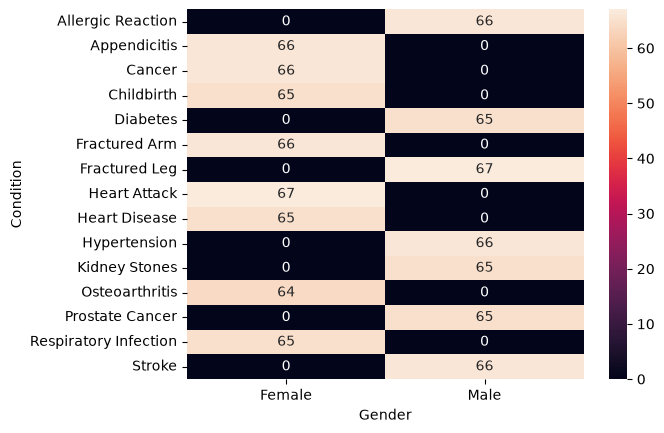

In [39]:
sns.heatmap(table, annot=True)
plt.show()

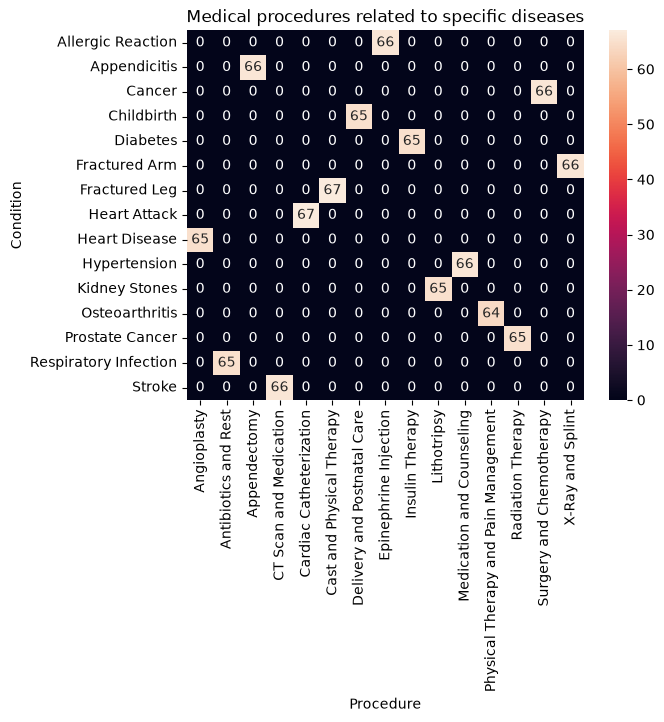

In [40]:
# The procedures relation to the medical conditions
tabcond=pd.crosstab(df["Condition"],df["Procedure"])
sns.heatmap(tabcond,annot=True)
plt.title("Medical procedures related to specific diseases")
plt.show()

Readmission  Gender
No           Female     7511.904762
             Male       5684.507042
Yes          Female    14223.913043
             Male       9764.705882
Name: Cost, dtype: float64
  Readmission  Gender          Cost
0          No  Female   7511.904762
1          No    Male   5684.507042
2         Yes  Female  14223.913043
3         Yes    Male   9764.705882


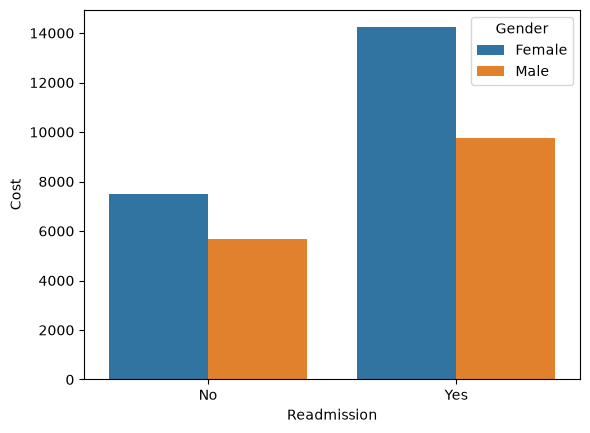

In [41]:
#how readmission of a patient is relared to gender and cost
readm=df.groupby(["Readmission","Gender"])["Cost"].mean()

print(readm)
#convert to dataframe
readm=readm.reset_index()
print(readm)
sns.barplot(x="Readmission",y="Cost",hue="Gender",data=readm)
#average cost of patients who have been readmitted are lower than patients 
#who have prolonged stay in hospital
plt.show()

# predicting cost of procedures using simple and multiple linear regression

## Simple linear regression

In [42]:
x=df[["Satisfaction"]]
y=df["Cost"]

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [44]:
x_tr,x_test,y_tr,y_test=train_test_split(x,y,test_size=0.2)

In [45]:
model_lm=LinearRegression().fit(x_tr,y_tr)

In [46]:
model_lm

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-4060.36]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Satisfaction']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.291e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [47]:
p=model_lm.predict(x_test)
p[0:10]

array([10730.40867664, 14790.77306838, 14790.77306838, 10730.40867664,
        6670.04428489, 10730.40867664, 10730.40867664, 10730.40867664,
        2609.67989314, 10730.40867664])

In [48]:
y_test[0:10]

882    20000
136    10000
259    18000
675    20000
93     25000
839     6000
321    20000
542    20000
533      500
677     6000
Name: Cost, dtype: int64

## R2_score for simple linear regression shows poor results

In [49]:
print(r2_score(y_test,p))

0.24223098447474012


In [50]:
print(model_lm.coef_)
print(model_lm.intercept_)

[-4060.36439175]
22911.501851875215


## Multiple linear regression

In [51]:
#multiple linear regression with all columns
x=df.drop("Cost",axis=1)
catcols=x.select_dtypes(include="object")
catcols.head()

C:\Users\CHANDAN KUMAR\AppData\Local\Temp\ipykernel_14184\2644335671.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  catcols=x.select_dtypes(include="object")


,Gender,Condition,Procedure,Readmission,Outcome
0,Female,Heart Disease,Angioplasty,No,Recovered
1,Male,Diabetes,Insulin Therapy,Yes,Stable
2,Female,Fractured Arm,X-Ray and Splint,No,Recovered
3,Male,Stroke,CT Scan and Medication,Yes,Stable
4,Female,Cancer,Surgery and Chemotherapy,No,Recovered


In [52]:
encoded_x=pd.get_dummies(columns=catcols.columns,data=x)

In [53]:
encoded_x.head()

,Age,Length_of_Stay,Satisfaction,Gender_Female,Gender_Male,Condition_Allergic Reaction,Condition_Appendicitis,Condition_Cancer,Condition_Childbirth,Condition_Diabetes,...,Procedure_Lithotripsy,Procedure_Medication and Counseling,Procedure_Physical Therapy and Pain Management,Procedure_Radiation Therapy,Procedure_Surgery and Chemotherapy,Procedure_X-Ray and Splint,Readmission_No,Readmission_Yes,Outcome_Recovered,Outcome_Stable
0,45,5,4,True,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,True,False
1,60,3,3,False,True,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,True
2,32,1,5,True,False,False,False,False,False,False,...,False,False,False,False,False,True,True,False,True,False
3,75,7,2,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
4,50,10,4,True,False,False,False,True,False,False,...,False,False,False,False,True,False,True,False,True,False


In [54]:
encoded_x.dtypes

Age                                               int64
Length_of_Stay                                    int64
Satisfaction                                      int64
Gender_Female                                      bool
Gender_Male                                        bool
Condition_Allergic Reaction                        bool
Condition_Appendicitis                             bool
Condition_Cancer                                   bool
Condition_Childbirth                               bool
Condition_Diabetes                                 bool
Condition_Fractured Arm                            bool
Condition_Fractured Leg                            bool
Condition_Heart Attack                             bool
Condition_Heart Disease                            bool
Condition_Hypertension                             bool
Condition_Kidney Stones                            bool
Condition_Osteoarthritis                           bool
Condition_Prostate Cancer                       

In [55]:
x_tr,x_test,y_tr,y_test=train_test_split(encoded_x,y,test_size=0.2)
model_lm=LinearRegression().fit(x_tr,y_tr)
p=model_lm.predict(x_test)

In [56]:
print(r2_score(y_test,p))

1.0


<Axes: xlabel='Cost'>

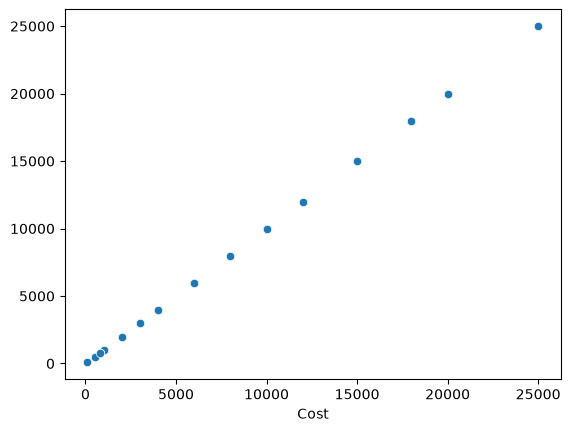

In [57]:
sns.scatterplot(x=y_test,y=p)

Why is R² Coming Out as 1?
Direct Leakage: You might have accidentally included the Target column (or a duplicate of it) in your feature set 
.
Proxy Columns: One of your columns is a direct transformation of the target (e.g., Target is "Price" and you included "Price + Tax").

### analysing the reason of r2_core 1.0

#first you need to check if you have accidentally included the target variable cost here as a feature in X which is not the case here

In [58]:
df_new =pd.concat([encoded_x,y],axis=1)

In [59]:
df_new.corr()["Cost"].sort_values(ascending=False)

Cost                                              1.000000
Condition_Cancer                                  0.574852
Procedure_Surgery and Chemotherapy                0.574852
Readmission_Yes                                   0.412281
Condition_Prostate Cancer                         0.398768
Procedure_Radiation Therapy                       0.398768
Condition_Heart Attack                            0.335614
Procedure_Cardiac Catheterization                 0.335614
Age                                               0.303816
Gender_Female                                     0.287602
Outcome_Recovered                                 0.245640
Procedure_Angioplasty                             0.227366
Condition_Heart Disease                           0.227366
Condition_Childbirth                              0.124524
Procedure_Delivery and Postnatal Care             0.124524
Length_of_Stay                                    0.114206
Condition_Stroke                                  0.0564

### Creating OLS regression model from statsmodels

In [62]:
#rename columns

In [63]:
encoded_x.columns = [c.replace(' ', '_') for c in encoded_x.columns]

In [64]:
encoded_x.columns = [c.replace('-', '') for c in encoded_x.columns]

In [65]:
encoded_x.columns

Index(['Age', 'Length_of_Stay', 'Satisfaction', 'Gender_Female', 'Gender_Male',
       'Condition_Allergic_Reaction', 'Condition_Appendicitis',
       'Condition_Cancer', 'Condition_Childbirth', 'Condition_Diabetes',
       'Condition_Fractured_Arm', 'Condition_Fractured_Leg',
       'Condition_Heart_Attack', 'Condition_Heart_Disease',
       'Condition_Hypertension', 'Condition_Kidney_Stones',
       'Condition_Osteoarthritis', 'Condition_Prostate_Cancer',
       'Condition_Respiratory_Infection', 'Condition_Stroke',
       'Procedure_Angioplasty', 'Procedure_Antibiotics_and_Rest',
       'Procedure_Appendectomy', 'Procedure_CT_Scan_and_Medication',
       'Procedure_Cardiac_Catheterization',
       'Procedure_Cast_and_Physical_Therapy',
       'Procedure_Delivery_and_Postnatal_Care',
       'Procedure_Epinephrine_Injection', 'Procedure_Insulin_Therapy',
       'Procedure_Lithotripsy', 'Procedure_Medication_and_Counseling',
       'Procedure_Physical_Therapy_and_Pain_Management',
    

In [66]:
from statsmodels.formula.api import ols
str_x = " + ".join( encoded_x.columns)
print(str_x)

Age + Length_of_Stay + Satisfaction + Gender_Female + Gender_Male + Condition_Allergic_Reaction + Condition_Appendicitis + Condition_Cancer + Condition_Childbirth + Condition_Diabetes + Condition_Fractured_Arm + Condition_Fractured_Leg + Condition_Heart_Attack + Condition_Heart_Disease + Condition_Hypertension + Condition_Kidney_Stones + Condition_Osteoarthritis + Condition_Prostate_Cancer + Condition_Respiratory_Infection + Condition_Stroke + Procedure_Angioplasty + Procedure_Antibiotics_and_Rest + Procedure_Appendectomy + Procedure_CT_Scan_and_Medication + Procedure_Cardiac_Catheterization + Procedure_Cast_and_Physical_Therapy + Procedure_Delivery_and_Postnatal_Care + Procedure_Epinephrine_Injection + Procedure_Insulin_Therapy + Procedure_Lithotripsy + Procedure_Medication_and_Counseling + Procedure_Physical_Therapy_and_Pain_Management + Procedure_Radiation_Therapy + Procedure_Surgery_and_Chemotherapy + Procedure_XRay_and_Splint + Readmission_No + Readmission_Yes + Outcome_Recovered 

In [67]:
df_new=pd.concat([encoded_x,y],axis=1)

In [68]:
df_new=df_new.rename(columns={"y":"Cost"})

In [69]:
ols_model=ols(f"Cost~{str_x}",data=df_new).fit()

In [70]:
ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Cost   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.674e+29
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:29:46   Log-Likelihood:                 21169.
No. Observations:                 984   AIC:                        -4.230e+04
Df Residuals:                     965   BIC:                        -4.221e+04
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
==========================================================================================================================
                                                             coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------
Intercept                                               3013.9535   4.29e-11   7.02e+13      0.000    3013.953    3013.953
Gender_Female[T.True]                                   3197.0930   2.16e-11   1.48e+14      0.000    3197.093    3197.093
Gender_Male[T.True]                                     -183.1395   2.21e-11   -8.3e+12      0.000    -183.140    -183.140
Condition_Allergic_Reaction[T.True]                    -3648.8372   1.71e-11  -2.13e+14      0.000   -3648.837   -3648.837
Condition_Appendicitis[T.True]                         -1388.9535   9.75e-12  -1.42e+14      0.000   -1388.953   -1388.953
Condition_Cancer[T.True]                                7111.0465   9.91e-12   7.18e+14      0.000    7111.047    7111.047
Condition_Childbirth[T.True]                             611.0465   8.86e-12    6.9e+13      0.000     611.047     611.047
Condition_Diabetes[T.True]                             -1145.9302   8.08e-12  -1.42e+14      0.000   -1145.930   -1145.930
Condition_Fractured_Arm[T.True]                        -5138.9535   1.45e-11  -3.53e+14      0.000   -5138.953   -5138.953
Condition_Fractured_Leg[T.True]                        -2198.8372   7.61e-12  -2.89e+14      0.000   -2198.837   -2198.837
Condition_Heart_Attack[T.True]                          5163.9535   1.48e-11   3.48e+14      0.000    5163.953    5163.953
Condition_Heart_Disease[T.True]                         2111.0465   8.31e-12   2.54e+14      0.000    2111.047    2111.047
Condition_Hypertension[T.True]                         -1645.9302   1.39e-11  -1.19e+14      0.000   -1645.930   -1645.930
Condition_Kidney_Stones[T.True]                         -698.8372   8.61e-12  -8.12e+13      0.000    -698.837    -698.837
Condition_Osteoarthritis[T.True]                       -1836.0465   1.15e-11   -1.6e+14      0.000   -1836.047   -1836.047
Condition_Prostate_Cancer[T.True]                       6301.1628   1.19e-11   5.28e+14      0.000    6301.163    6301.163
Condition_Respiratory_Infection[T.True]                -3436.0465   1.04e-11   -3.3e+14      0.000   -3436.047   -3436.047
Condition_Stroke[T.True]                                2854.0698   1.27e-11   2.25e+14      0.000    2854.070    2854.070
Procedure_Angioplasty[T.True]                           2111.0465   8.31e-12   2.54e+14      0.000    2111.047    2111.047
Procedure_Antibiotics_and_Rest[T.True]                 -3436.0465   1.04e-11   -3.3e+14      0.000   -3436.047   -3436.047
Procedure_Appendectomy[T.True]                         -1388.9535   9.75e-12  -1.42e+14      0.000   -1388.953   -1388.953
Procedure_CT_Scan_and_Medication[T.True]                2854.0698   1.27e-11   2.25e+14      0.000    2854.070    2854.070
Procedur

In [71]:
#from the statsmodels we can see that durbin watson test whould have a value between 1.5 and 2.5 but it shows .39
#The model shows stron positive autocorrelation
#Jarque bera test p value less than .05 shows model has heterscedascity

<Axes: xlabel='Cost', ylabel='Density'>

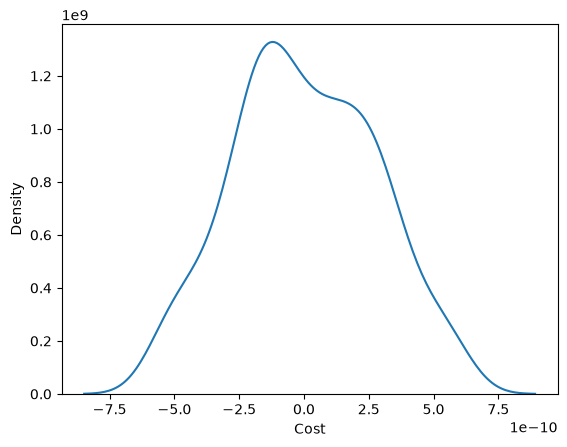

In [72]:
#print the kdeplot of residual
resid=y_test-p
sns.kdeplot(resid)
#shows normal distribution

In [73]:
#instead of performing log transormation trying to do forward selection

In [74]:
y=df_new["Cost"]

In [75]:
encoded_x.columns

Index(['Age', 'Length_of_Stay', 'Satisfaction', 'Gender_Female', 'Gender_Male',
       'Condition_Allergic_Reaction', 'Condition_Appendicitis',
       'Condition_Cancer', 'Condition_Childbirth', 'Condition_Diabetes',
       'Condition_Fractured_Arm', 'Condition_Fractured_Leg',
       'Condition_Heart_Attack', 'Condition_Heart_Disease',
       'Condition_Hypertension', 'Condition_Kidney_Stones',
       'Condition_Osteoarthritis', 'Condition_Prostate_Cancer',
       'Condition_Respiratory_Infection', 'Condition_Stroke',
       'Procedure_Angioplasty', 'Procedure_Antibiotics_and_Rest',
       'Procedure_Appendectomy', 'Procedure_CT_Scan_and_Medication',
       'Procedure_Cardiac_Catheterization',
       'Procedure_Cast_and_Physical_Therapy',
       'Procedure_Delivery_and_Postnatal_Care',
       'Procedure_Epinephrine_Injection', 'Procedure_Insulin_Therapy',
       'Procedure_Lithotripsy', 'Procedure_Medication_and_Counseling',
       'Procedure_Physical_Therapy_and_Pain_Management',
    

### linear regression model selection through forward selection

#printing the R2_score through forward selection

In [76]:
col=[]
j=0
for i in encoded_x.columns:
    j+=1
    col.append(i)
    x=encoded_x.loc[:,col]
    x_tr,x_test,y_tr,y_test=train_test_split(x,y,test_size=0.2)
    model_lm=LinearRegression().fit(x_tr,y_tr)
    print(f"model:{j}",model_lm)
    p=model_lm.predict(x_test)
    print("features:",x_test.columns)
    print(r2_score(y_test,p))

model:1 LinearRegression()
features: Index(['Age'], dtype='str')
0.13530783469815977
model:2 LinearRegression()
features: Index(['Age', 'Length_of_Stay'], dtype='str')
0.1536718794167954
model:3 LinearRegression()
features: Index(['Age', 'Length_of_Stay', 'Satisfaction'], dtype='str')
0.10717440164735392
model:4 LinearRegression()
features: Index(['Age', 'Length_of_Stay', 'Satisfaction', 'Gender_Female'], dtype='str')
0.2875382058855248
model:5 LinearRegression()
features: Index(['Age', 'Length_of_Stay', 'Satisfaction', 'Gender_Female',
       'Gender_Male'],
      dtype='str')
0.38503279271230606
model:6 LinearRegression()
features: Index(['Age', 'Length_of_Stay', 'Satisfaction', 'Gender_Female', 'Gender_Male',
       'Condition_Allergic_Reaction'],
      dtype='str')
0.29879317810484074
model:7 LinearRegression()
features: Index(['Age', 'Length_of_Stay', 'Satisfaction', 'Gender_Female', 'Gender_Male',
       'Condition_Allergic_Reaction', 'Condition_Appendicitis'],
      dtype='str')

In [77]:
# the data shows a linear relationship of cost with the condition as well as with procedure

### Performing non linear regression

In [78]:
#perorming non linear regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

In [79]:
encoded_x.shape

(984, 39)

#### Decision tree regression

In [80]:
x=df.drop("Cost",axis=1)

y=df["Cost"]
catcols=x.select_dtypes(include="object")
encoded_x=pd.get_dummies(columns=catcols.columns,data=x)
x_tr,x_test,y_tr,y_test=train_test_split(encoded_x,y,test_size=0.2)

model_lm=DecisionTreeRegressor().fit(x_tr,y_tr)
p=model_lm.predict(x_test)
p_tr=model_lm.predict(x_tr)
print("test_score",r2_score(y_test,p))
print("training_score",r2_score(y_tr,p_tr))

test_score 1.0
training_score 1.0


C:\Users\CHANDAN KUMAR\AppData\Local\Temp\ipykernel_14184\1082016965.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  catcols=x.select_dtypes(include="object")


In [81]:
# shows again a value of 1.0

### KNN Regression with gridsearchCV model

In [82]:
x=df.drop("Cost",axis=1)

y=df["Cost"]
catcols=x.select_dtypes(include="object")
encoded_x=pd.get_dummies(columns=catcols.columns,data=x)
x_tr,x_test,y_tr,y_test=train_test_split(encoded_x,y,test_size=0.2)
param_grid = {
    'n_neighbors': np.arange(1, 20),        # Test k from 1 to 20
    'weights': ['uniform', 'distance'],     # Test different weight functions
    'metric': ['euclidean', 'manhattan']    # Test different distance metrics
}
gv=GridSearchCV(KNeighborsRegressor(),param_grid, cv=5, scoring='neg_mean_squared_error', verbose=1)
gv=gv.fit(x_tr,y_tr)
print(gv.best_params_)
model_lm=KNeighborsRegressor(n_neighbors=gv.best_params_["n_neighbors"],metric=gv.best_params_["metric"],weights=gv.best_params_["weights"]).fit(x_tr,y_tr)
p=model_lm.predict(x_test)
p_tr=model_lm.predict(x_tr)
print("test_score",r2_score(y_test,p))
print("training_score",r2_score(y_tr,p_tr))

C:\Users\CHANDAN KUMAR\AppData\Local\Temp\ipykernel_14184\4209472074.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  catcols=x.select_dtypes(include="object")


Fitting 5 folds for each of 76 candidates, totalling 380 fits
{'metric': 'manhattan', 'n_neighbors': np.int64(1), 'weights': 'uniform'}
test_score 0.9958437046601375
training_score 1.0


In [83]:
#The data shows a accuracy of 1.0 with all models
#indicating it may be synthetic data or very simple data

# Final model obtained from forward selection

In [84]:
#to prevent data leak you can keep the following x
x=encoded_x.loc[:,['Age', 'Length_of_Stay', 'Satisfaction', 'Gender_Female', 'Gender_Male',
       'Procedure_Angioplasty', 'Procedure_Antibiotics and Rest',
       'Procedure_Appendectomy', 'Procedure_CT Scan and Medication',
       'Procedure_Cardiac Catheterization',
       'Procedure_Cast and Physical Therapy',
       'Procedure_Delivery and Postnatal Care',
       'Procedure_Epinephrine Injection', 'Procedure_Insulin Therapy',
       'Procedure_Lithotripsy', 'Procedure_Medication and Counseling',
       'Procedure_Physical Therapy and Pain Management']]
y=df["Cost"]
x_tr,x_test,y_tr,y_test=train_test_split(x,y,test_size=0.2)
model_lm=LinearRegression().fit(x_tr,y_tr)
p=model_lm.predict(x_test)
print("features:",x_test.columns)
print("test_score:",r2_score(y_test,p))
p_tr=model_lm.predict(x_tr)
print("training_score:",r2_score(y_tr,p_tr))

features: Index(['Age', 'Length_of_Stay', 'Satisfaction', 'Gender_Female', 'Gender_Male',
       'Procedure_Angioplasty', 'Procedure_Antibiotics and Rest',
       'Procedure_Appendectomy', 'Procedure_CT Scan and Medication',
       'Procedure_Cardiac Catheterization',
       'Procedure_Cast and Physical Therapy',
       'Procedure_Delivery and Postnatal Care',
       'Procedure_Epinephrine Injection', 'Procedure_Insulin Therapy',
       'Procedure_Lithotripsy', 'Procedure_Medication and Counseling',
       'Procedure_Physical Therapy and Pain Management'],
      dtype='str')
test_score: 0.8907412496826699
training_score: 0.8896171650975006
